# Predicting Steam game popularity using community tags
## Draft portfolio
Name: Thomas Radulescu  
Student number: C00302068

### 1 Project question
Can the community tags attached to a Steam game help classify its estimated ownership as low, medium or high? This draft trains one simple decision tree. Comparing several models is left for the final portfolio.

The work follows the CRISP-DM stages from Chapter 5: understanding the question and data, preparing the data, modelling, and evaluation. There is no deployed application at this stage.

### 2 Data selection
This draft uses `steam.csv` from Nik Davis's Steam Store Games dataset, collected around May 2019. It combines Steam and SteamSpy information. The supplied copy is included so the analysis can run without an API key or another download.

The selected fields are `appid` (game identifier), `name`, `steamspy_tags` (semicolon-separated tags) and `owners` (estimated ownership interval). The main CSV contains a limited selection of tags per game rather than every community tag. Owners are estimates, not exact sales or current player counts.

Python and Pandas handle the CSV and cleaning, Matplotlib produces charts, and Scikit-learn provides a decision tree and evaluation tools. A notebook keeps explanations, code and results together.

In [1]:
# Name: Thomas Radulescu | Student number: ADD YOUR STUDENT NUMBER
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

DATA = Path('data/steam.csv')
df = pd.read_csv(DATA)
print('Original shape:', df.shape)
print(df[['appid', 'name', 'steamspy_tags', 'owners']].head().to_string(index=False))

Original shape: (27075, 18)
 appid                      name                steamspy_tags            owners
    10            Counter-Strike       Action;FPS;Multiplayer 10000000-20000000
    20     Team Fortress Classic       Action;FPS;Multiplayer  5000000-10000000
    30             Day of Defeat FPS;World War II;Multiplayer  5000000-10000000
    40        Deathmatch Classic       Action;FPS;Multiplayer  5000000-10000000
    50 Half-Life: Opposing Force            FPS;Action;Sci-fi  5000000-10000000


### 3 Data preparation
Following Chapter 6, check missing values and duplicate identifiers before modelling. Rows without tags or ownership cannot answer this question, so remove them rather than guess values. Keep only one row per app ID. Validate the ownership interval before extracting its lower bound.

The categories are defined in advance from the ownership bands: low has a lower bound below 20,000; medium has a lower bound from 20,000 to below 100,000; high has a lower bound of at least 100,000. These are project choices, not official Steam categories. The interval estimates make the boundary approximate.

Only tag presence is used as a predictor. Ratings, price, name, app ID and ownership values are excluded from the model inputs. Scaling is unnecessary for binary inputs to a tree.

In [2]:
df = df[['appid', 'name', 'steamspy_tags', 'owners']].copy()
print('Missing values before cleaning:')
print(df.isna().sum().to_string())
print('Duplicate app IDs:', df['appid'].duplicated().sum())
before = len(df)
df = df.dropna(subset=['appid', 'steamspy_tags', 'owners']).drop_duplicates('appid')
df = df[df['steamspy_tags'].str.strip().ne('')].copy()
bounds = df['owners'].str.extract(r'^(\d+)-(\d+)$').apply(pd.to_numeric)
valid = bounds.notna().all(axis=1) & (bounds[0] <= bounds[1])
df = df.loc[valid].copy()
df['owners_lower'] = bounds.loc[valid, 0].astype(int)
def popularity(lower):
    if lower < 20000:
        return 'Low'
    if lower < 100000:
        return 'Medium'
    return 'High'
df['popularity'] = df['owners_lower'].apply(popularity)
print('Rows removed:', before - len(df))
print('Rows retained:', len(df))
labels = ['Low', 'Medium', 'High']
print(df['popularity'].value_counts().reindex(labels).to_string())

train, test = train_test_split(df, test_size=0.2, random_state=42,
                              stratify=df['popularity'])
print('Training rows:', len(train), 'Test rows:', len(test))

Missing values before cleaning:
appid            0
name             0
steamspy_tags    0
owners           0
Duplicate app IDs: 0
Rows removed: 0
Rows retained: 27075
popularity
Low       18596
Medium     4754
High       3725
Training rows: 21660 Test rows: 5415


### 4 Exploring the training data
The 80/20 split keeps the same approximate category proportions in both parts. The test data is set aside before exploring tag patterns. These charts show the category balance and the most frequent tags among high-ownership training games. A common tag is not necessarily a cause of popularity.

Most common tags among high-ownership training games:
steamspy_tags
Indie           963
Action          928
Adventure       508
Strategy        492
Free to Play    472
RPG             385
Casual          377
Simulation      259
Multiplayer     226
FPS             192


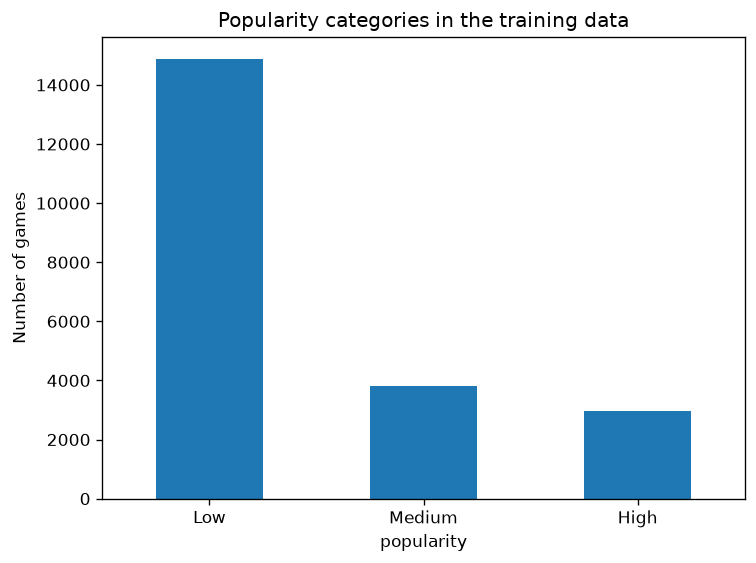

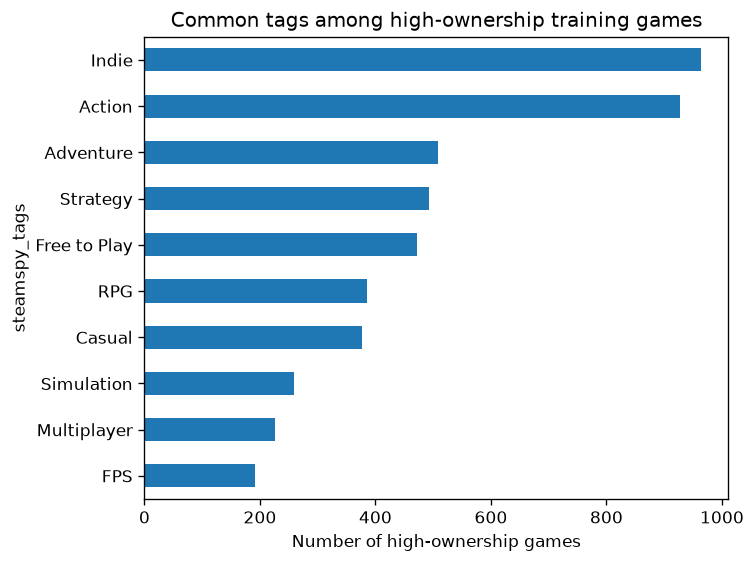

In [3]:
train['popularity'].value_counts().reindex(labels).plot.bar(rot=0)
plt.ylabel('Number of games')
plt.title('Popularity categories in the training data')
plt.tight_layout()
plt.show()
high_tags = train.loc[train['popularity'].eq('High'), 'steamspy_tags'].str.split(';').explode()
print('Most common tags among high-ownership training games:')
print(high_tags.value_counts().head(10).to_string())
high_tags.value_counts().head(10).sort_values().plot.barh()
plt.xlabel('Number of high-ownership games')
plt.title('Common tags among high-ownership training games')
plt.tight_layout()
plt.show()

### 5 Training the model
Convert each tag into a column containing 1 when present and 0 when absent. Learn the available columns from training games only; ignore any new tags found only in the test set.

A decision tree asks a sequence of questions about tags to choose a category. Decision-tree classification is mentioned in Chapter 6. It fits the categorical question better than the linear regression example in Chapter 3a. A maximum depth of 5 and minimum leaf size of 30 keep the model small. These settings are fixed for this draft rather than repeatedly adjusted against the test results.

Tag features: 333
Training accuracy: 0.6972
Test accuracy: 0.6962
Always predict Low baseline accuracy: 0.6868
              precision    recall  f1-score   support

         Low       0.70      0.98      0.82      3719
      Medium       0.47      0.06      0.11       951
        High       0.62      0.09      0.15       745

    accuracy                           0.70      5415
   macro avg       0.60      0.38      0.36      5415
weighted avg       0.65      0.70      0.60      5415



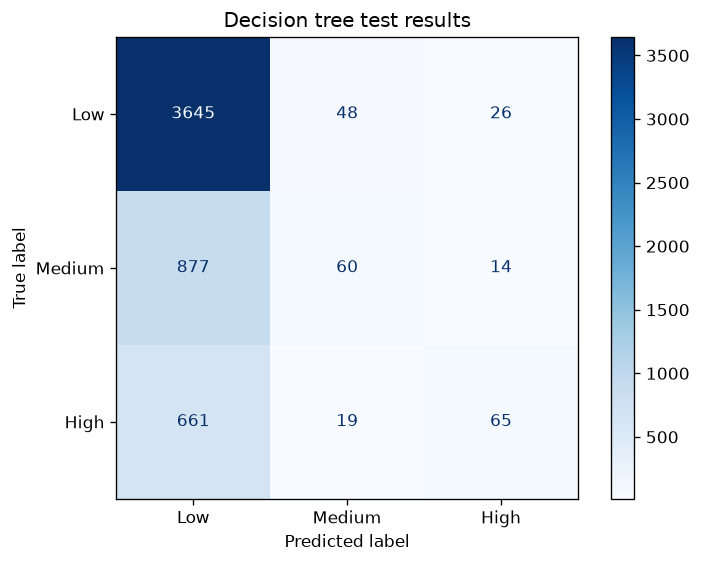

In [4]:
X_train = train['steamspy_tags'].str.get_dummies(sep=';')
X_test = test['steamspy_tags'].str.get_dummies(sep=';').reindex(columns=X_train.columns, fill_value=0)
y_train = train['popularity']
y_test = test['popularity']
model = DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, random_state=42)
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print('Tag features:', X_train.shape[1])
print('Training accuracy:', round(model.score(X_train, y_train), 4))
print('Test accuracy:', round(accuracy_score(y_test, predictions), 4))
majority = y_train.mode()[0]
baseline = (y_test == majority).mean()
print('Always predict', majority, 'baseline accuracy:', round(baseline, 4))
print(classification_report(y_test, predictions, labels=labels, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=labels, cmap='Blues')
plt.title('Decision tree test results')
plt.tight_layout()
plt.show()

### 6 Validation
Accuracy is the fraction of test games classified correctly. The majority-class baseline checks whether the tree improves on simply predicting the most common training category. Precision measures how often predictions of a category are correct, while recall measures how many actual games in that category are found. Macro F1 weights each category equally. The confusion matrix shows which categories are confused.

This is one held-out test split, not cross-validation. Related games may occur in both sets, and the result does not demonstrate performance on future releases.

### 7 Draft conclusion
The decision tree achieved **69.6% test accuracy**, compared with **68.7%** for always predicting the most common category. This is a difference of **0.9 percentage points**. The improvement is small. Recall is about 98% for Low, 6% for Medium and 9% for High; macro F1 is about 0.36. The tree mostly predicts Low and is poor at finding the other two categories. This is a weak first model, not a reliable popularity predictor.

This answers the main question at a basic level: a tag-only model can produce popularity predictions, but the results are limited. The data is from 2019, ownership is estimated, and the selected tags may have developed after a game became popular. This analysis therefore describes associations in an existing snapshot; it does not establish that adding a tag causes success or that the model predicts pre-release success.

The frequency chart addresses which tags occur most among high-ownership games. A detailed comparison of tag combinations and different classifiers remains for the final version. Next steps are to examine mistakes, compare one other basic classifier, and consider whether the fuller tag file improves the analysis.

### Sources
- Nik Davis, Steam Store Games dataset, collected around May 2019, CC BY 4.0: https://www.kaggle.com/datasets/nikdavis/steam-store-games (downloaded 2 November 2026). The included data is unchanged.